# 일곱 가지 stream mode

**이 노트북에서 할 일**

1. 노드 둘짜리 그래프를 `stream`으로 실행해, 사건이 하나씩 나오는 모습을 봅니다.
2. 스트림 모드 일곱을 한 목록으로 골라 한 번 실행하고, 모드마다 사건 수·나온 자리·모양을 봅니다.
3. 두 번 실행·모드마다 따로 실행·체크포인터 없이 실행해, 사건 수가 어떻게 되는지 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
그래서 모드 `messages`의 사건은 0개이고, 실제 모델로 보는 일은 02절 몫입니다.
노드 둘은 매번 같은 값을 내는 우리 코드라, 새 커널로 다시 실행해도 출력이 같습니다.
걸린 시간은 재지 않았습니다.

체크포인터는 메모리에만 저장하고, 읽거나 쓰는 파일은 없습니다.
그래서 임시 폴더를 만들지 않고, 실습 폴더에도 파일을 남기지 않습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11, 체크포인터는 langgraph-checkpoint 4.2.0에 들어 있습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
사건이 하나씩 나오는 모습과, 일곱 모드가 내놓는 사건의 수·자리·모양을 보는 자리입니다.
6~9절은 같은 결과를 다른 방법으로 다시 받아 보는 자리이고, 실습 시간에 실행합니다.
셀 하나만 다시 실행하면 같은 스레드에 체크포인트가 이어 쌓여, 단계 번호와 체크포인트 수가 달라집니다.
처음 값으로 다시 보려면 2절 그래프 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch25-streaming`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 입력 딕셔너리 topic 배송 문의가 회색 상자 graph.stream 모드 일곱을 한 목록으로, 파란 상자 우리 노드 둘 prepare 다음 write를 거쳐 노란 상자 스트림 사건 스물셋으로 이어집니다. 그 아래에 노란 상자 셋이 나란히 놓입니다. 칸 값과 진행 값에서 values 셋 updates 둘 custom 둘, 저장과 작업에서 checkpoints 넷 tasks 넷 debug 여덟, 모델의 답에서 messages 없음인 그림](attachment:01-1-한-실행에서-받은-일곱-모드.png)

위에서 아래로 읽습니다.
초록 상자는 넣은 입력, 회색 상자는 라이브러리 메서드, 파란 상자는 우리가 적은 노드입니다.
노란 상자는 모두 노트북 4절에서 출력으로 확인한 값입니다.
맨 아래 세 상자는 사건이 무엇에서 나오느냐로 이 절이 나눈 무리이고, 셋 사이에 차례는 없습니다.
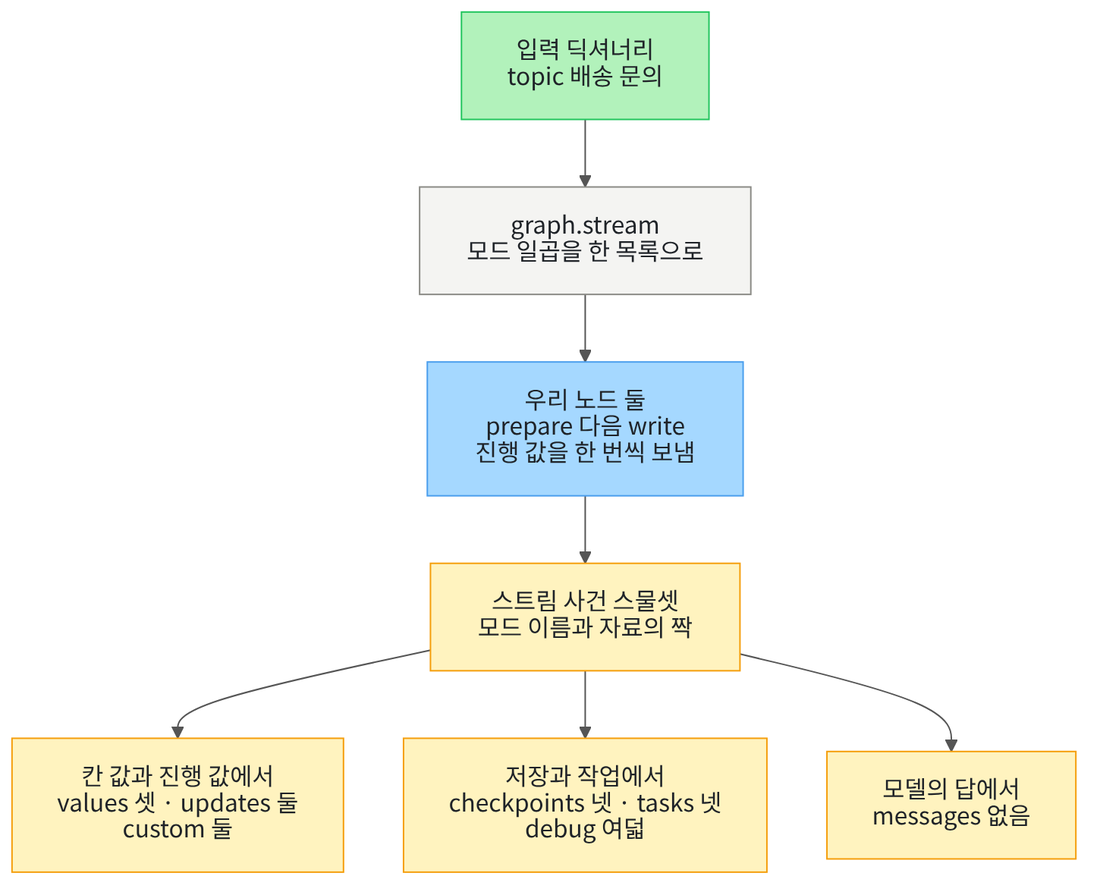

## 1. 준비

Ch 13부터 그래프는 `invoke`로 실행해, 다 끝난 뒤의 칸 값만 받았습니다.
이 절에서는 메서드 `stream`으로 실행하며, 실행 도중 생기는 일을 하나씩 받습니다.
절 제목의 stream mode는 그 일을 어떤 방식으로 받을지 고르는 이름입니다.
이 노트북에서는 스트림 모드라고 쓰고, 4절에서 일곱 모드를 한 번에 받아 봅니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01절, 체크포인터 `InMemorySaver`는 Ch 23 01절과 같습니다.
새로 쓰는 이름은 `get_args`·`get_stream_writer`·`StreamMode` 셋이고, 쓰는 자리에서 하나씩 풉니다.
객체 `Command`와 함수 `interrupt`는 Ch 24 01절에서 쓴 이름이고, 9절에서만 씁니다.

In [2]:
# 그래프 이름(Ch 13 01절)·체크포인터(Ch 23 01절)와, 스트림에 쓸 이름을 가져옵니다
from typing import get_args
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
# get_stream_writer는 노드 안에서 진행 값을 보낼 쓰기 함수를 꺼내는 함수입니다
from langgraph.config import get_stream_writer
# StreamMode는 모드 이름 목록을 적은 형식, Command·interrupt는 Ch 24 01절에서 쓴 이름입니다
from langgraph.types import Command, StreamMode, interrupt

print("langgraph.config에서 가져온 이름:", "get_stream_writer")
print("langgraph.types에서 가져온 이름:", "Command, StreamMode, interrupt")

langgraph.config에서 가져온 이름: get_stream_writer
langgraph.types에서 가져온 이름: Command, StreamMode, interrupt


**결과 읽기** — 출력 줄 `langgraph.types에서 가져온 이름: Command, StreamMode, interrupt`가 보입니다.
함수 `get_args`는 파이썬에 들어 있는 모듈 `typing`의 함수이고, 4절에서 씁니다.

## 2. 노드 둘짜리 그래프

그래프는 Ch 13 01절처럼 노드 둘을 한 줄로 잇습니다.
노드 `prepare`는 문의 제목의 앞뒤 빈칸을 지우고, 노드 `write`는 안내 초안을 씁니다.
먼저 상태 형식을 만듭니다.
칸 `topic`은 문의 제목, 칸 `draft`는 안내 초안이고, 둘 다 규칙이 없어 새 값이 오면 덮어씁니다.

In [3]:
# 문의 제목과 안내 초안 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 두 칸 모두 규칙 없음)
class DraftState(TypedDict):
    topic: str
    draft: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 노드 둘짜리 그래프가 이 상태 형식을 씁니다.

진행 값은 노드가 실행 도중에 직접 보내는 값입니다.
부엌에서 요리하는 사람이 「재료 손질 끝」 하고 알려 주는 말과 같습니다.
이 절에서는 노드가 딕셔너리 `{"stage": …, "progress": …}`를 보냅니다.

함수 `get_stream_writer`는 노드 안에서 불러, 진행 값을 보낼 쓰기 함수를 꺼냅니다.
꺼낸 쓰기 함수에 값을 넣어 부르면, 그 값이 스트림으로 나갑니다.
다음 셀은 진행 값 50을 보낸 뒤, 칸 `topic`의 앞뒤 빈칸을 지운 글을 내는 노드입니다.

In [4]:
# 진행 값을 보내고, 문의 제목의 앞뒤 빈칸을 지운 글을 칸 topic에 내는 노드입니다
def prepare(state):
    # get_stream_writer()는 이 실행의 쓰기 함수를 내놓고, 쓰기 함수는 받은 값을 스트림으로 보냅니다
    writer = get_stream_writer()
    writer({"stage": "prepare", "progress": 50})
    return {"topic": state["topic"].strip()}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
진행 값의 숫자 50은 우리가 정한 값이고, 라이브러리가 계산한 값이 아닙니다.
메서드 `strip`은 글 앞뒤의 빈칸을 지운 새 글을 내놓습니다.

다음 셀은 진행 값 100을 보낸 뒤, 문의 제목 뒤에 「안내 초안」을 붙인 글을 칸 `draft`에 내는 노드입니다.

In [5]:
# 진행 값을 보내고, 문의 제목 뒤에 「안내 초안」을 붙인 글을 칸 draft에 내는 노드입니다
def write(state):
    writer = get_stream_writer()
    writer({"stage": "write", "progress": 100})
    draft = state["topic"] + " 안내 초안"
    return {"draft": draft}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
두 노드 모두 진행 값을 한 번씩 보내므로, 한 실행에서 진행 값은 둘입니다.

다음 셀은 노드 둘을 이어 그래프를 만들고, Ch 23 01절처럼 체크포인터 `InMemorySaver`를 붙여 컴파일합니다.
체크포인터를 뺀 그래프와는 8절에서 견줍니다.

In [6]:
# 노드 둘을 START → prepare → write → END로 잇고, 체크포인터를 붙여 컴파일합니다
builder = StateGraph(DraftState)
builder.add_node("prepare", prepare)
builder.add_node("write", write)
builder.add_edge(START, "prepare")
builder.add_edge("prepare", "write")
builder.add_edge("write", END)
graph = builder.compile(checkpointer=InMemorySaver())
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['prepare', 'write']


**결과 읽기** — 출력 줄 `등록한 노드: ['prepare', 'write']`가 보입니다.

## 3. 사건을 하나씩 받기

메서드 `stream`은 `invoke`와 같은 입력과 설정을 받습니다.
다만 끝난 뒤의 칸 값 대신, 실행 도중 생긴 일을 하나씩 꺼낼 수 있는 객체를 내놓습니다.
Ch 6 04절 모델의 `stream()`처럼, 이 객체는 제너레이터(generator)입니다.
제너레이터는 `for`가 하나를 꺼낼 때마다 다음 값을 만들어, 부르는 줄에서는 실행이 시작되지 않습니다.

다음 셀은 `stream`을 부르기만 하고 꺼내지는 않은 채, 객체 종류와 체크포인트 수를 봅니다.
실행 전에 예상해 봅니다.
실행이 아직 시작되지 않았다면, 이 스레드의 체크포인트는 0개일 것입니다.

In [7]:
# 입력을 넣어 stream을 부르고, 아직 꺼내지 않은 채 객체 종류와 체크포인트 수를 봅니다
first_input = {"topic": " 배송 문의 ", "draft": ""}
default_config = {"configurable": {"thread_id": "default"}}
default_stream = graph.stream(first_input, default_config)
print("stream이 준 객체 종류:", type(default_stream).__name__)
# 실행이 시작됐다면 이 스레드에 체크포인트가 쌓였을 것입니다
before_history = list(graph.get_state_history(default_config))
print("꺼내기 전 체크포인트 수:", len(before_history))

stream이 준 객체 종류: generator
꺼내기 전 체크포인트 수: 0


**결과 읽기** — 출력 줄 `stream이 준 객체 종류: generator`와 `꺼내기 전 체크포인트 수: 0`이 보입니다.
메서드 `stream`을 부른 줄에서는 그래프가 아직 한 노드도 실행하지 않았습니다.

스트림 사건은 메서드 `stream`이 한 번에 하나씩 내놓는 값입니다.
홈통에서 물이 한 방울씩 떨어질 때의 방울 하나와 같습니다.
이 절 코드에서는 `for`가 한 번 꺼낼 때마다 받는 값이 스트림 사건 하나입니다.
다음 셀은 사건을 하나씩 꺼내며 바로 출력하고, 다 꺼낸 뒤 체크포인트 수를 봅니다.

In [8]:
# for로 사건을 하나씩 꺼내 바로 출력하고, 다 꺼낸 뒤 체크포인트 수를 봅니다
for event in default_stream:
    print("받은 사건:", event)
after_history = list(graph.get_state_history(default_config))
print("다 꺼낸 뒤 체크포인트 수:", len(after_history))
# 인자 stream_mode를 주지 않았을 때 이 그래프가 쓰는 모드 이름입니다
print("이 그래프의 기본 모드:", graph.stream_mode)

받은 사건: {'prepare': {'topic': '배송 문의'}}
받은 사건: {'write': {'draft': '배송 문의 안내 초안'}}
다 꺼낸 뒤 체크포인트 수: 4
이 그래프의 기본 모드: updates


**결과 읽기** — 출력 줄 `받은 사건: {'prepare': {'topic': '배송 문의'}}`와 `받은 사건: {'write': {'draft': '배송 문의 안내 초안'}}`가 보입니다.
사건은 둘이고, 노드 이름과 그 노드가 낸 갱신이 짝지어 있습니다.
출력 줄 `다 꺼낸 뒤 체크포인트 수: 4`로, 꺼내는 동안 실행이 끝까지 갔습니다.
출력 줄 `이 그래프의 기본 모드: updates`는 모드를 고르지 않았을 때 쓰는 모드 이름입니다.

두 노드 모두 진행 값을 보냈는데, 받은 사건에는 진행 값이 없습니다.
진행 값은 모드 `custom`을 골라야 받을 수 있기 때문입니다.
설치판 `langgraph/types.py` 138~141행은 쓰기 함수가 모드 `custom`이 아니면 아무 일도 하지 않는다고 적습니다.
4절에서는 모드를 모두 골라 이 진행 값도 함께 받습니다.

## 4. 일곱 모드를 한 실행에서 받기

스트림 모드(stream mode)는 한 실행에서 생긴 일 가운데 무엇을 어떤 모양으로 받을지 고르는 이름입니다.
홈통 아래 여러 구멍 가운데 어느 구멍에 그릇을 댈지 고르는 것과 같습니다.
이 절 코드에서는 메서드 `stream`의 인자 `stream_mode`에 넣는 글입니다.
3절은 이 인자를 주지 않아, 기본 모드 `updates`를 썼습니다.

설치한 판이 받는 모드 이름은 `langgraph.types`의 `StreamMode`에 적혀 있습니다.
이 이름은 정해 둔 글 가운데 하나만 받는다고 적은 형식이고, Ch 19 02절의 `Literal`과 같은 모양입니다.
함수 `get_args`는 이런 형식에서 정해 둔 글들을 꺼내 줍니다.
다음 셀은 모드 이름을 꺼내 목록으로 만듭니다.

In [9]:
# 설치한 langgraph가 받는 모드 이름 일곱을 꺼내 목록으로 만듭니다
all_modes = list(get_args(StreamMode))
print("모드 수:", len(all_modes))
print("모드 이름:", all_modes)

모드 수: 7
모드 이름: ['values', 'updates', 'checkpoints', 'tasks', 'debug', 'messages', 'custom']


**결과 읽기** — 출력 줄 `모드 수: 7`과 `모드 이름: ['values', 'updates', 'checkpoints', 'tasks', 'debug', 'messages', 'custom']`이 보입니다.
이 노트북은 모드를 모두 이 차례로 적습니다.
공식 문서의 모드 표도 같은 이름 일곱을 적습니다.

인자 `stream_mode`에는 모드 이름 하나를 글로 줄 수도, 여럿을 목록으로 줄 수도 있습니다.
목록으로 주면 사건 하나가 (모드 이름, 자료) 짝으로 나와, 어느 모드에서 온 사건인지 가를 수 있습니다.
다음 셀은 그래프를 한 번 실행하며 받은 사건을 차례대로 목록에 모으는 함수입니다.

In [10]:
# 그래프를 한 번 실행하며 받은 사건을 차례대로 목록에 모아 내놓습니다
def collect_events(graph_to_run, graph_input, config, modes):
    events = []
    # stream_mode에 목록을 주면, 사건 하나가 (모드 이름, 자료) 짝으로 나옵니다
    for event in graph_to_run.stream(graph_input, config, stream_mode=modes):
        events.append(event)
    return events

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 사건을 모두 모은 뒤에 목록을 내놓습니다.
화면에 바로 보여야 하는 곳에서는 3절처럼 `for` 안에서 사건을 바로 씁니다.
이 절은 사건 수와 차례를 세려고 목록에 모읍니다.

다음 셀은 일곱 모드를 한 목록으로 골라, 새 스레드 `all-1`로 한 번 실행합니다.
실행 전에 예상해 봅니다.
3절의 사건 둘보다 훨씬 많은 사건이 나오고, 이 스레드의 체크포인트는 3절처럼 넷일 것입니다.

In [11]:
# 일곱 모드를 한 목록으로 골라, 새 스레드 all-1로 그래프를 한 번 실행합니다
all_config = {"configurable": {"thread_id": "all-1"}}
all_events = collect_events(graph, first_input, all_config, all_modes)
print("받은 사건 수:", len(all_events))
first_event = all_events[0]
print("첫 사건의 종류와 길이:", type(first_event).__name__, len(first_event))
print("첫 사건의 모드 이름:", first_event[0])
all_history = list(graph.get_state_history(all_config))
print("이 스레드의 체크포인트 수:", len(all_history))

받은 사건 수: 23
첫 사건의 종류와 길이: tuple 2
첫 사건의 모드 이름: checkpoints
이 스레드의 체크포인트 수: 4


**결과 읽기** — 출력 줄 `받은 사건 수: 23`입니다.
출력 줄 `첫 사건의 종류와 길이: tuple 2`로, 사건 하나가 둘짜리 튜플입니다.
출력 줄 `첫 사건의 모드 이름: checkpoints`로, 맨 앞 사건은 모드 `checkpoints`에서 왔습니다.
출력 줄 `이 스레드의 체크포인트 수: 4`는 3절과 같습니다.
모드를 일곱 골라도 그래프는 한 번만 실행되었습니다.

다음 셀은 사건 목록에서 한 모드의 사건이 몇 번째에 나왔는지 찾는 함수입니다.
자리는 사람이 세는 대로 1부터 셉니다.

In [12]:
# 사건 목록에서 한 모드의 사건이 몇 번째(1부터 셈)에 나왔는지 목록으로 내놓습니다
def positions_of(events, mode):
    places = []
    for index in range(len(events)):
        # 사건 하나는 (모드 이름, 자료) 짝이라, [0]이 모드 이름입니다
        if events[index][0] == mode:
            places.append(index + 1)
    return places

**결과 읽기** — 정의 셀이라 출력이 없습니다.
목록의 자리는 0부터 세므로, 찾은 자리에 1을 더해 적습니다.

다음 셀은 모드마다 사건 수와 나온 자리를 한 줄씩 출력합니다.

In [13]:
# 모드마다 사건 수와, 스물세 사건 가운데 나온 자리를 한 줄씩 출력합니다
print("모드 | 사건 수 | 나온 자리")
for mode in all_modes:
    places = positions_of(all_events, mode)
    print(mode, "|", len(places), "|", places)

모드 | 사건 수 | 나온 자리
values | 3 | [3, 12, 21]
updates | 2 | [9, 18]
checkpoints | 4 | [1, 4, 13, 22]
tasks | 4 | [6, 10, 15, 19]
debug | 8 | [2, 5, 7, 11, 14, 16, 20, 23]
messages | 0 | []
custom | 2 | [8, 17]


**결과 읽기** — 라벨 줄 아래 첫 줄은 `values | 3 | [3, 12, 21]`, 둘째 줄은 `updates | 2 | [9, 18]`입니다.
그 아래는 `checkpoints | 4 | [1, 4, 13, 22]`와 `tasks | 4 | [6, 10, 15, 19]`, `debug | 8 | [2, 5, 7, 11, 14, 16, 20, 23]`입니다.
마지막 두 줄은 `messages | 0 | []`와 `custom | 2 | [8, 17]`입니다.
사건 수를 모두 더하면 3 + 2 + 4 + 4 + 8 + 0 + 2 = 23으로, 앞 셀의 사건 수와 같습니다.

진행 값(`custom`)은 8·17번째에 나왔고, 바로 뒤 9·18번째에 노드의 갱신(`updates`)이 나왔습니다.
노드가 실행 도중에 보낸 진행 값이, 노드가 끝나고 낸 갱신보다 먼저 옵니다.
모드 `messages`는 사건이 0개입니다.
이 그래프의 노드는 모델을 부르지 않았고, 모델의 답을 받는 일은 02절에서 봅니다.

## 5. 모드마다 무엇이 나오는가

다음 셀은 모드마다 첫 사건의 자료가 무슨 자료형이고 어떤 키를 가졌는지 한 줄씩 봅니다.
사건 목록의 자리는 0부터 세므로, 나온 자리에서 1을 빼서 꺼냅니다.

In [14]:
# 모드마다 첫 사건의 자료가 어떤 모양인지(자료형과 키) 한 줄씩 봅니다
print("모드 | 자료형 | 키")
for mode in all_modes:
    places = positions_of(all_events, mode)
    if len(places) == 0:
        print(mode, "| 사건 없음")
    else:
        # 나온 자리는 1부터 세었고 목록의 자리는 0부터라, 1을 빼서 꺼냅니다
        first_data = all_events[places[0] - 1][1]
        print(mode, "|", type(first_data).__name__, "|", list(first_data))

모드 | 자료형 | 키
values | dict | ['topic', 'draft']
updates | dict | ['prepare']
checkpoints | dict | ['config', 'parent_config', 'values', 'metadata', 'next', 'tasks']
tasks | dict | ['id', 'name', 'input', 'triggers']
debug | dict | ['step', 'timestamp', 'type', 'payload']
messages | 사건 없음
custom | dict | ['stage', 'progress']


**결과 읽기** — 라벨 줄 아래 여섯 모드의 자료형은 모두 `dict`이고, `messages | 사건 없음` 한 줄만 다릅니다.
모드 `values`의 키 `['topic', 'draft']`는 상태 형식의 칸 둘입니다.
모드 `updates`의 키 `['prepare']`는 노드 이름이고, 모드 `custom`의 키 `['stage', 'progress']`는 우리가 보낸 진행 값 그대로입니다.
나머지 셋은 라이브러리가 정한 키이고, 아래 셀에서 하나씩 봅니다.

다음 셀은 칸 값과 진행 값에 관한 세 모드(`values`·`updates`·`custom`)의 사건만 나온 차례대로 출력합니다.
사건 목록을 `for mode, data in …`로 돌면, 둘짜리 튜플의 앞 값이 `mode`에, 뒤 값이 `data`에 들어갑니다.
Ch 6 04절에서 `for role, content in …`으로 메시지 짝을 풀었던 것과 같은 모양입니다.

In [15]:
# 칸 값에 관한 세 모드(values·updates·custom)의 사건만 나온 차례대로 출력합니다
state_modes = ["values", "updates", "custom"]
for mode, data in all_events:
    if mode in state_modes:
        print(mode, "|", data)

values | {'topic': ' 배송 문의 ', 'draft': ''}
custom | {'stage': 'prepare', 'progress': 50}
updates | {'prepare': {'topic': '배송 문의'}}
values | {'topic': '배송 문의', 'draft': ''}
custom | {'stage': 'write', 'progress': 100}
updates | {'write': {'draft': '배송 문의 안내 초안'}}
values | {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}


**결과 읽기** — 일곱 줄이 나옵니다.
첫 줄 `values | {'topic': ' 배송 문의 ', 'draft': ''}`는 넣은 입력 그대로이고, 빈칸이 남아 있습니다.
그다음 `custom | {'stage': 'prepare', 'progress': 50}` 뒤에 `updates | {'prepare': {'topic': '배송 문의'}}`가 옵니다.
마지막 줄 `values | {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}`은 다 끝난 뒤의 칸 값 전체입니다.

모드 `values`는 칸 전체를 보내므로, 칸이 많아지면 사건 하나가 커집니다.
모드 `updates`는 노드가 바꾼 칸만 보내고, 모드 `custom`은 노드가 보낸 값을 그대로 보냅니다.
진행 값은 상태의 칸에 들어가지 않으므로, 셀 주석의 「칸 값에 관한 세 모드」는 칸 값과 진행 값에 관한 세 모드로 읽습니다.
노드마다 진행 값을 보낸 뒤에 노드가 끝나므로, 진행 값 사건이 갱신 사건보다 먼저입니다.

다음 셀은 모드 `checkpoints`의 사건을 봅니다.
사건 하나는 체크포인트를 저장할 때마다 나오고, 설치판 설명은 `get_state()`와 같은 모양이라고 적습니다.
Ch 23 01절 체크포인트 목록처럼 단계 번호·만든 자리·다음 노드·칸 값을 한 줄씩 출력합니다.

In [16]:
# 모드 checkpoints의 사건마다 단계 번호·만든 자리·다음 노드·칸 값을 봅니다(Ch 23 01절 목록과 같은 칸)
print("단계 번호 | 만든 자리 | 다음 노드 | 칸 값")
for mode, data in all_events:
    if mode == "checkpoints":
        # 키 config에는 실행마다 달라지는 아이디가 있어 출력하지 않습니다
        saved = data["metadata"]
        print(saved["step"], "|", saved["source"], "|", data["next"], "|", data["values"])

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
-1 | input | ['__start__'] | {}
0 | loop | ['prepare'] | {'topic': ' 배송 문의 ', 'draft': ''}
1 | loop | ['write'] | {'topic': '배송 문의', 'draft': ''}
2 | loop | [] | {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}


**결과 읽기** — 라벨 줄 아래 첫 줄은 `-1 | input | ['__start__'] | {}`입니다.
둘째 줄은 `0 | loop | ['prepare'] | {'topic': ' 배송 문의 ', 'draft': ''}`입니다.
그 아래 `1 | loop | ['write']`와 `2 | loop | []`로 시작하는 두 줄이 이어집니다.
단계 -1은 입력을 받은 때, 단계 0은 입력을 칸에 넣은 뒤, 단계 1·2는 노드 둘이 끝난 뒤입니다.

Ch 23 01절의 노드 하나짜리 그래프는 한 번 실행에 체크포인트가 셋(단계 -1·0·1)이었습니다.
노드가 둘인 이 그래프는 둘째 노드를 마친 단계 2까지 넷입니다.
다만 Ch 23 01절 `get_state_history`는 최신 것부터 내놓았고, 스트림은 저장한 차례대로 내놓습니다.

모드 `tasks`는 작업의 시작과 끝을 알립니다.
작업(task)은 Ch 23 05절에서 본 대로, 한 단계에서 노드 하나를 한 번 실행하는 일입니다.
다음 셀은 사건마다 노드 이름과, 시작 사건인지 끝 사건인지를 봅니다.
끝 사건에만 키 `result`가 있어, 그 키가 있는지로 가릅니다.

In [17]:
# 모드 tasks의 사건마다 노드 이름과, 시작 사건인지 끝 사건인지를 봅니다
for mode, data in all_events:
    if mode == "tasks":
        # 끝 사건에만 키 result가 있습니다(키 id의 값은 실행마다 달라 출력하지 않음)
        if "result" in data:
            print(data["name"], "| 끝 |", list(data), "| result:", data["result"])
        else:
            print(data["name"], "| 시작 |", list(data))

prepare | 시작 | ['id', 'name', 'input', 'triggers']
prepare | 끝 | ['id', 'name', 'error', 'result', 'interrupts'] | result: {'topic': '배송 문의'}
write | 시작 | ['id', 'name', 'input', 'triggers']
write | 끝 | ['id', 'name', 'error', 'result', 'interrupts'] | result: {'draft': '배송 문의 안내 초안'}


**결과 읽기** — 첫 줄은 `prepare | 시작 | ['id', 'name', 'input', 'triggers']`입니다.
둘째 줄은 `prepare | 끝 | ['id', 'name', 'error', 'result', 'interrupts'] | result: {'topic': '배송 문의'}`입니다.
셋째·넷째 줄은 노드 `write`의 시작과 끝입니다.
끝 사건의 키 `result`는 모드 `updates`가 보낸 그 노드의 갱신과 같습니다.
공식 문서는 이 모드가 작업의 결과와 오류를 함께 알린다고 적습니다.

모드 `debug`는 모드 `checkpoints`·`tasks`의 사건을 한 모양으로 감싸 다시 보냅니다.
사건마다 키 `type`에 무엇을 감쌌는지 적혀 있습니다.
다음 셀은 이 키의 값만 모아 봅니다.

In [18]:
# 모드 debug의 사건마다 키 type의 값을 모아, 무엇을 감싸 보냈는지 봅니다
debug_types = []
for mode, data in all_events:
    if mode == "debug":
        # 키 timestamp의 시각은 실행마다 달라 출력하지 않습니다
        debug_types.append(data["type"])
print("debug 사건의 type:", debug_types)

debug 사건의 type: ['checkpoint', 'checkpoint', 'task', 'task_result', 'checkpoint', 'task', 'task_result', 'checkpoint']


**결과 읽기** — 출력 줄 `debug 사건의 type: ['checkpoint', 'checkpoint', 'task', 'task_result', 'checkpoint', 'task', 'task_result', 'checkpoint']`입니다.
값 `checkpoint` 넷은 체크포인트 사건, `task`와 `task_result` 둘씩은 작업의 시작·끝 사건과 짝이 맞습니다.
4절 표에서 debug 사건 여덟은 모두 체크포인트 사건이나 작업 사건 바로 뒤에 나왔습니다.
그래서 debug 사건 수 8은 체크포인트 사건 4와 작업 사건 4를 더한 값입니다.

## 6. invoke가 내놓는 값

Ch 13부터 써 온 `invoke`는 다 끝난 뒤의 칸 값 전체를 내놓았습니다.
다음 셀은 같은 입력을 새 스레드 `invoke`에서 실행하고, 4절 실행의 마지막 `values` 사건과 견줍니다.
실행 전에 예상해 봅니다.
마지막 `values` 사건도 다 끝난 뒤의 칸 값 전체이니, 둘은 같을 것입니다.

In [19]:
# 같은 입력을 invoke로 실행한 결과와, 4절 실행의 마지막 values 사건을 견줍니다
invoke_config = {"configurable": {"thread_id": "invoke"}}
invoke_result = graph.invoke(first_input, invoke_config)
print("invoke 결과:", invoke_result)
last_values = None
for mode, data in all_events:
    if mode == "values":
        last_values = data
print("마지막 values 사건:", last_values)
print("둘이 같은가:", invoke_result == last_values)

invoke 결과: {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}
마지막 values 사건: {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}
둘이 같은가: True


**결과 읽기** — 출력 줄 `invoke 결과: {'topic': '배송 문의', 'draft': '배송 문의 안내 초안'}`와 `둘이 같은가: True`가 보입니다.
메서드 `invoke`는 사건을 하나씩 보여 주지 않고, 마지막 칸 값만 내놓습니다.
설치판 `langgraph/pregel/main.py` 3913~3955행은 `invoke`가 안에서 `stream`을 부르고, 마지막 `values` 사건을 남기는 자리입니다.
같은 실행을 한꺼번에 받느냐, 하나씩 받느냐의 차이입니다.

## 7. 두 번 받아도, 따로 받아도 같은가

다음 셀은 같은 입력을 새 스레드 `all-2`로 한 번 더 받아, 사건의 모드 이름 차례를 4절 실행과 한 자리씩 견줍니다.
노드 코드와 그래프 모양이 차례를 정하므로, 같아야 합니다.
체크포인트 아이디와 시각은 실행마다 달라, 모드 이름만 견줍니다.

In [20]:
# 새 스레드 all-2로 한 번 더 실행해, 사건 수와 모드 이름 차례가 4절 실행과 같은지 봅니다
second_config = {"configurable": {"thread_id": "all-2"}}
second_events = collect_events(graph, first_input, second_config, all_modes)
print("두 실행의 사건 수:", len(all_events), len(second_events))
same_order = True
for index in range(len(all_events)):
    if all_events[index][0] != second_events[index][0]:
        same_order = False
print("모드 이름 차례가 같은가:", same_order)
# 노드 코드와 그래프 모양이 정하는 차례라, 실행마다 같아야 합니다
assert same_order, "두 실행의 사건 차례가 같아야 합니다"

두 실행의 사건 수: 23 23
모드 이름 차례가 같은가: True


**결과 읽기** — 출력 줄 `두 실행의 사건 수: 23 23`과 `모드 이름 차례가 같은가: True`입니다.
모델을 부르지 않는 이 그래프는 몇 번 실행해도 사건 차례가 같습니다.
그래서 이 노트북의 사건 수와 자리는 새 커널로 다시 실행해도 같게 나옵니다.

모드를 일곱 함께 고르면, 모드 하나만 고를 때보다 사건이 줄거나 늘까요?
다음 셀은 모드마다 하나만 골라 새 스레드로 일곱 번 따로 실행하고, 4절 한 실행의 사건 수와 견줍니다.
모드 하나도 목록 `[mode]`로 주어, 사건이 짝으로 나오게 했습니다.

In [21]:
# 모드를 하나씩만 골라 새 스레드로 일곱 번 따로 실행하고, 4절 한 실행의 사건 수와 견줍니다
print("모드 | 한 실행에서 | 따로 실행에서")
for mode in all_modes:
    one_config = {"configurable": {"thread_id": "one-" + mode}}
    # 모드 하나도 목록 [mode]로 주어, 사건이 짝으로 나오게 합니다
    one_events = collect_events(graph, first_input, one_config, [mode])
    together = positions_of(all_events, mode)
    print(mode, "|", len(together), "|", len(one_events))

모드 | 한 실행에서 | 따로 실행에서
values | 3 | 3
updates | 2 | 2
checkpoints | 4 | 4
tasks | 4 | 4
debug | 8 | 8
messages | 0 | 0
custom | 2 | 2


**결과 읽기** — 라벨 줄 아래 일곱 줄에서 두 수가 모두 같습니다.
예를 들어 `debug | 8 | 8`과 `messages | 0 | 0`입니다.
모드를 함께 골라도, 한 모드가 받는 사건은 그 모드만 고를 때와 같았습니다.
여러 모드를 골라도 그래프는 한 번 실행되고, 사건마다 모드 이름이 붙어 나옵니다.

## 8. 체크포인터를 빼면

모드 `checkpoints`는 체크포인트를 저장할 때 나오므로, 체크포인터가 없으면 사건도 없을 것입니다.
공식 문서의 모드 표는 모드 `tasks`에도 체크포인터가 있어야 한다고 적습니다.
다음 셀은 2절의 설계 객체를 체크포인터 없이 다시 컴파일하고, 일곱 모드를 한 번 실행합니다.
체크포인터가 없으니 스레드 이름을 담은 설정도 넘기지 않습니다.

In [22]:
# 2절의 설계 객체를 체크포인터 없이 다시 컴파일하고, 일곱 모드를 한 목록으로 한 번 실행합니다
plain_graph = builder.compile()
# 체크포인터가 없으니 스레드 이름을 담은 설정도 넘기지 않습니다(None)
plain_events = collect_events(plain_graph, first_input, None, all_modes)
print("받은 사건 수:", len(plain_events))
plain_types = []
for mode, data in plain_events:
    if mode == "debug":
        plain_types.append(data["type"])
print("debug 사건의 type:", plain_types)

받은 사건 수: 15
debug 사건의 type: ['task', 'task_result', 'task', 'task_result']


**결과 읽기** — 출력 줄 `받은 사건 수: 15`로, 체크포인터가 있을 때의 23보다 여덟 줄었습니다.
출력 줄 `debug 사건의 type: ['task', 'task_result', 'task', 'task_result']`로, 체크포인트를 감싼 사건이 없습니다.

다음 셀은 모드마다 체크포인터가 있을 때와 없을 때의 사건 수를 한 줄씩 견줍니다.

In [23]:
# 모드마다 체크포인터가 있을 때와 없을 때의 사건 수를 한 줄씩 견줍니다
print("모드 | 체크포인터 있음 | 체크포인터 없음")
for mode in all_modes:
    with_saver = positions_of(all_events, mode)
    without_saver = positions_of(plain_events, mode)
    print(mode, "|", len(with_saver), "|", len(without_saver))

모드 | 체크포인터 있음 | 체크포인터 없음
values | 3 | 3
updates | 2 | 2
checkpoints | 4 | 0
tasks | 4 | 4
debug | 8 | 4
messages | 0 | 0
custom | 2 | 2


**결과 읽기** — 라벨 줄 아래 `checkpoints | 4 | 0`과 `debug | 8 | 4`에서만 수가 다릅니다.
줄 `tasks | 4 | 4`처럼, 작업 사건은 체크포인터가 없어도 넷이 나왔습니다.
설치한 판에서는 문서 표와 달리, 모드 `tasks`에 체크포인터가 필요하지 않았습니다.
이 노트북은 설치한 판의 출력을 기준으로 적습니다.
나머지 모드의 사건 수는 체크포인터와 관계없이 같았습니다.

## 9. 멈춤 표시와 이어 가기를 사건으로 받기

Ch 24 01절에서는 `invoke`로 멈춤 표시를 받고, `Command(resume=…)`로 사람의 답을 넘겨 이어 갔습니다.
그때는 결과의 키 `__interrupt__`로 멈춘 것을 알았고, 스트림 사건은 받지 않았습니다.
이 절에서는 같은 장면을 모드 `updates`로 받아 봅니다.

Ch 23 03절의 스레드 재개는 객체를 새로 만든 뒤 같은 스레드로 대화를 이어 가는 일이었습니다.
Ch 23 04·06절 스크립트의 단계 `resume`은 강제 종료 뒤 새 프로세스로 다시 실행하는 단계였습니다.
이 절 9절은 Ch 24의 장면, 곧 멈춰 기다리던 실행에 사람의 답을 넣어 이어 가는 일만 봅니다.
스트림 모드 일곱 가운데 이어 가기만 따로 받는 모드는 없습니다.

먼저 문의 제목과 사람의 답 칸을 둔 상태 형식을 새로 만듭니다.
칸 구성이 2절과 달라, 이름도 새로 붙입니다.

In [24]:
# 문의 제목과 사람의 답 칸을 둔 상태 형식을 만듭니다(칸 구성이 2절과 달라 새 이름)
class SendState(TypedDict):
    topic: str
    answer: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 Ch 24 01절의 `ask_only`처럼, 멈춤 표시로 사람에게 묻고 받은 답을 칸 `answer`에 내는 노드입니다.
질문 값은 문의 제목과 질문 글 `보낼까요?`를 담은 딕셔너리입니다.

In [25]:
# 멈춤 표시로 안내 초안을 보낼지 묻고, 받은 답을 칸 answer에 내는 노드입니다
def ask_send(state):
    question = {"topic": state["topic"], "question": "보낼까요?"}
    # interrupt는 처음 부를 때 이 줄에서 멈추고, 이어 갈 때는 사람의 답을 내놓습니다
    answer = interrupt(question)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 이 노드 하나로 그래프를 만들고, 체크포인터를 붙여 컴파일합니다.
Ch 24 01절에서 본 대로, 멈춤 표시를 쓰려면 체크포인터와 스레드 이름이 있어야 합니다.

In [26]:
# 노드 하나를 START → ask_send → END로 잇고, 체크포인터를 붙여 컴파일합니다
send_builder = StateGraph(SendState)
send_builder.add_node("ask_send", ask_send)
send_builder.add_edge(START, "ask_send")
send_builder.add_edge("ask_send", END)
send_graph = send_builder.compile(checkpointer=InMemorySaver())
send_config = {"configurable": {"thread_id": "send"}}
print("등록한 노드:", list(send_builder.nodes))

등록한 노드: ['ask_send']


**결과 읽기** — 출력 줄 `등록한 노드: ['ask_send']`입니다.

다음 셀은 첫 실행을 모드 `updates`로 받아, 사건마다 키를 출력합니다.
멈춤 표시 항목에는 아이디도 있어, 질문 값만 꺼냅니다.
실행 전에 예상해 봅니다.
노드가 멈춤 표시에서 멈추므로, 노드의 갱신 대신 멈춤 표시가 사건으로 나올 것입니다.

In [27]:
# 첫 실행을 모드 updates로 받아, 사건마다 키와 멈춤 표시의 질문 값을 봅니다
send_input = {"topic": "배송 문의", "answer": "대기"}
for event in send_graph.stream(send_input, send_config, stream_mode="updates"):
    print("사건의 키:", list(event))
    # 멈춤 표시 항목에는 아이디도 있어, 속성 value의 질문 값만 꺼냅니다
    if "__interrupt__" in event:
        print("질문 값:", event["__interrupt__"][0].value)

사건의 키: ['__interrupt__']
질문 값: {'topic': '배송 문의', 'question': '보낼까요?'}


**결과 읽기** — 사건은 하나이고, 출력 줄 `사건의 키: ['__interrupt__']`입니다.
Ch 24 01절 `invoke` 결과에 생겼던 키 `__interrupt__`가, 모드 `updates`에서는 사건 하나로 나왔습니다.
출력 줄 `질문 값: {'topic': '배송 문의', 'question': '보낼까요?'}`는 노드가 함수 `interrupt`에 넣은 딕셔너리 그대로입니다.

다음 셀은 사람의 답 `approve`를 `Command(resume=…)`에 담아, 같은 스레드로 이어 가며 모드 `updates`로 받습니다.
실행 전에 예상해 봅니다.
노드가 답을 받아 끝나고, 노드의 갱신 하나가 사건으로 나올 것입니다.

In [28]:
# 사람의 답 "approve"를 Command의 자리 resume에 담아 같은 스레드로 이어 가며, 모드 updates로 받습니다
for event in send_graph.stream(Command(resume="approve"), send_config, stream_mode="updates"):
    print("받은 사건:", event)

받은 사건: {'ask_send': {'answer': 'approve'}}


**결과 읽기** — 출력 줄 `받은 사건: {'ask_send': {'answer': 'approve'}}` 하나입니다.
이어 가기는 따로 이름 붙은 사건이 아니라, 이어 간 노드가 끝나며 낸 갱신 한 줄로 보였습니다.
멈춤 표시와 이어 가기 모두 이번에는 모드 `updates`의 사건으로 받았습니다.

## 정리

1. 메서드 `stream`은 제너레이터를 내놓았고, `for`로 꺼낼 때 실행이 시작되어 사건이 하나씩 나왔습니다.
2. 스트림 모드 일곱을 한 목록으로 고르자 한 실행에서 사건 23개가 나왔습니다. 노드가 모델을 부르지 않고 글만 내서, `messages`만 0개였습니다.
3. 체크포인터를 빼자 `checkpoints` 사건이 사라지고 `debug`가 줄었지만, `tasks`는 넷 그대로였습니다.

02절에서는 실제 모델을 부르는 노드로, 모드 `messages`의 스트림 청크와 진행 값을 한 실행에서 함께 받습니다.